train (11959, 28, 28, 3) (11959,)
counts: [ 852 2181 1085 2026  849  993 2330 1643]
val (1712, 28, 28, 3) (1712,)
counts: [122 312 155 290 122 143 333 235]
test (3421, 28, 28, 3) (3421,)
counts: [244 624 311 579 243 284 666 470]


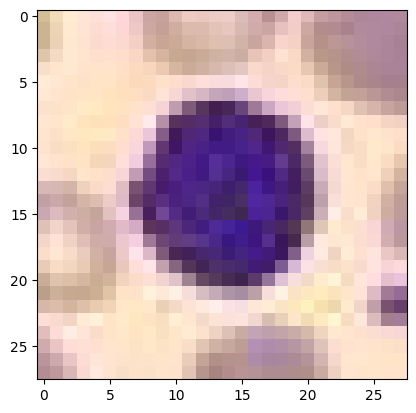

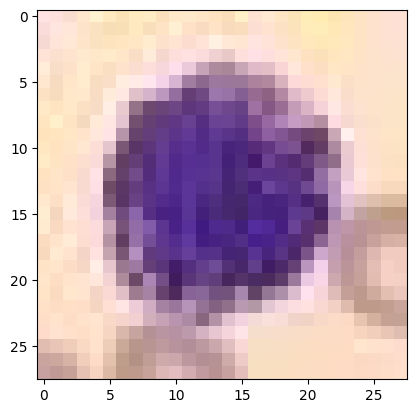

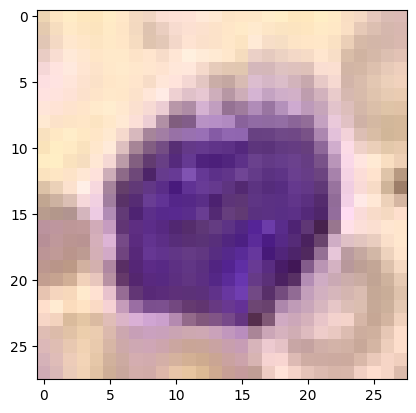

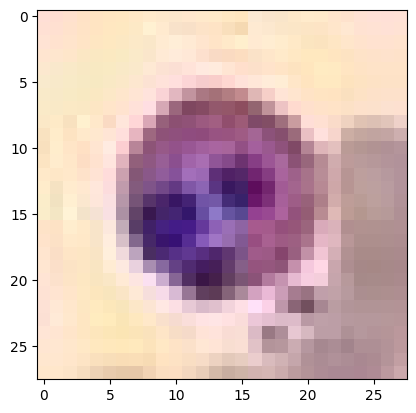

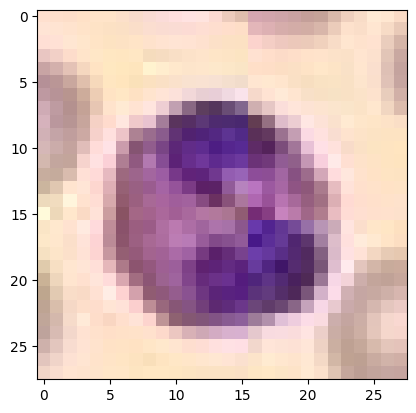

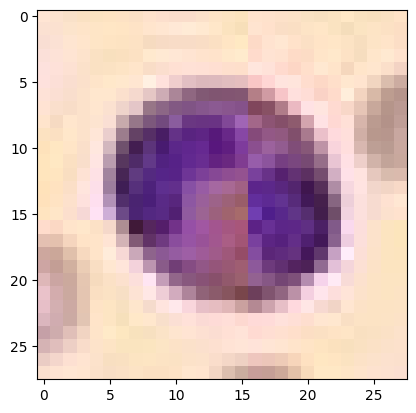

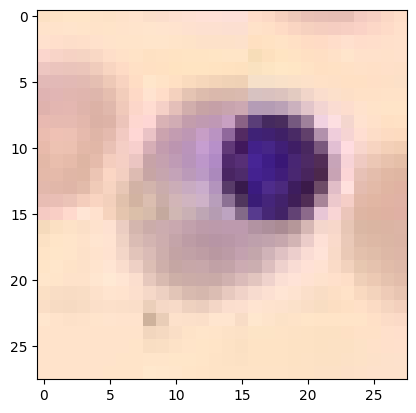

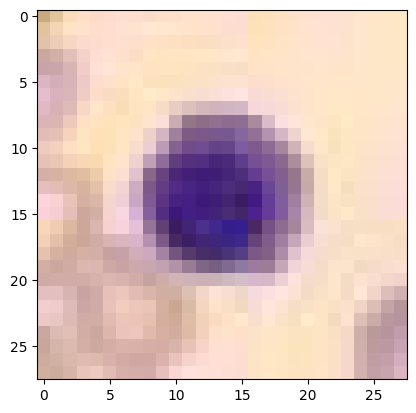

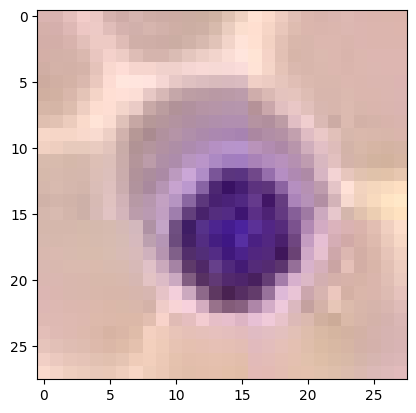

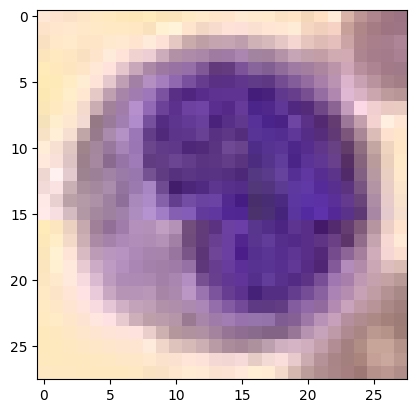

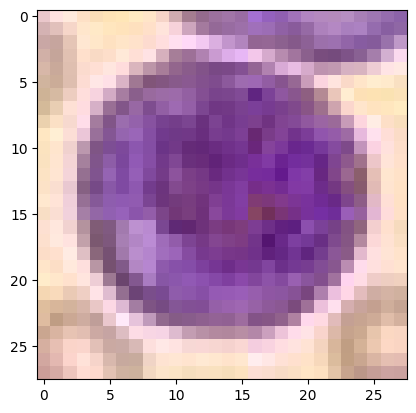

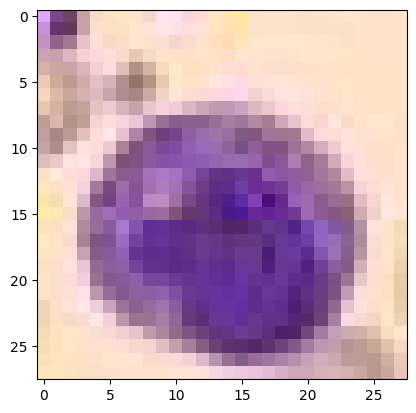

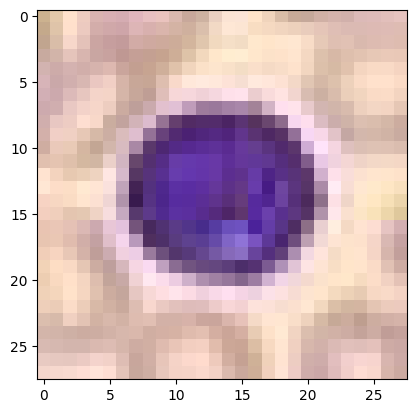

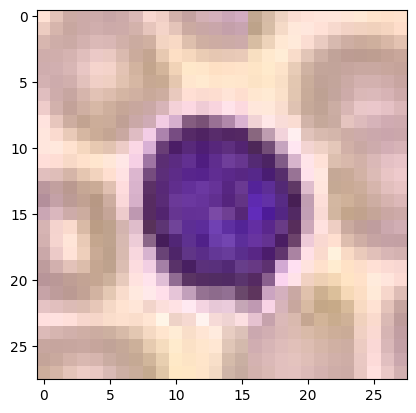

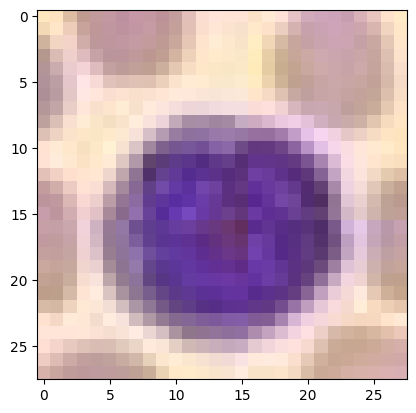

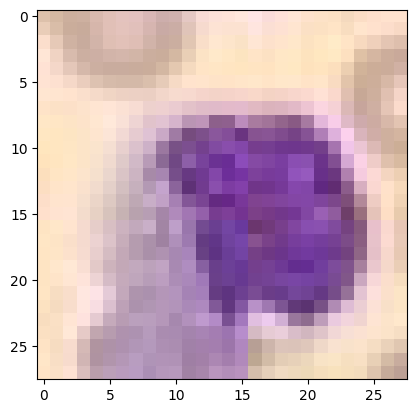

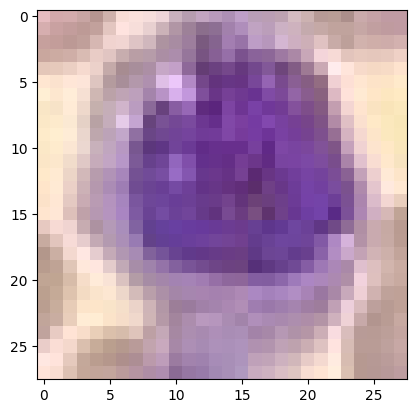

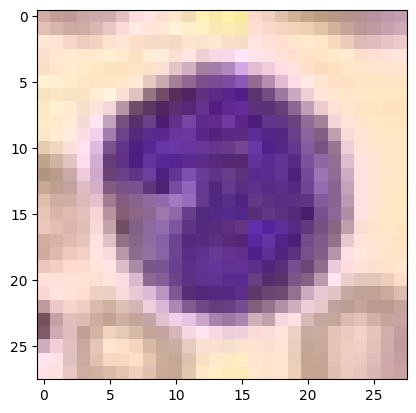

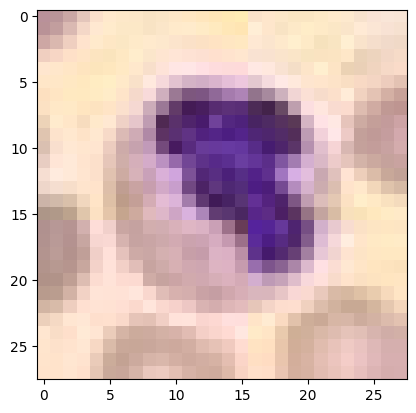

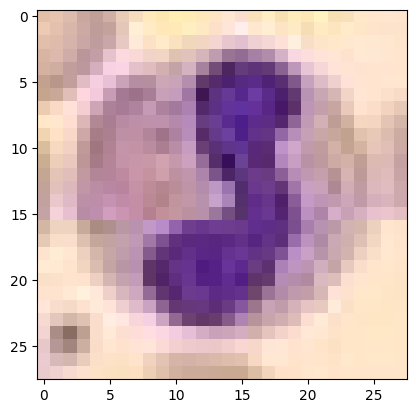

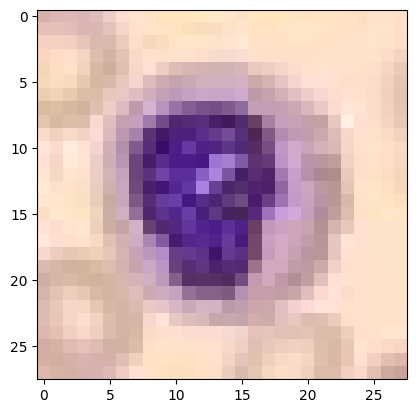

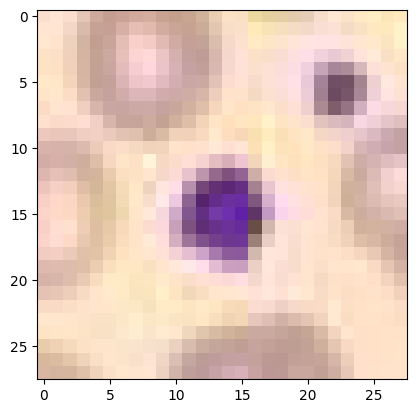

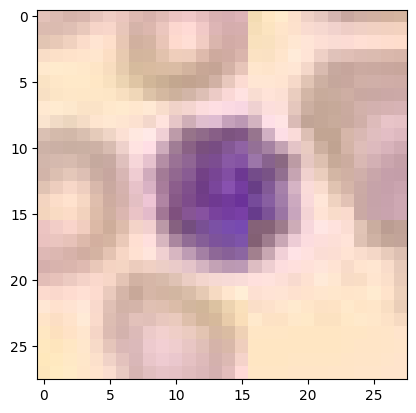

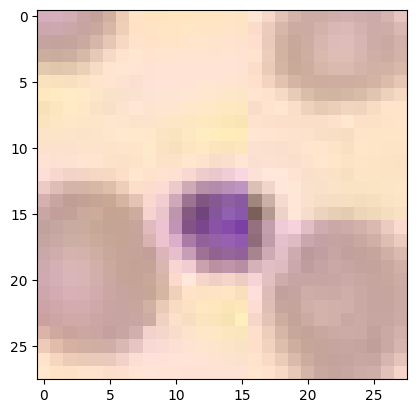

In [1]:
%matplotlib inline
from pathlib import Path
import cv2
import numpy as np
import matplotlib.pyplot as plt
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import SGDClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
)

SEED = 42
DATA_PATH = Path("BloodMNIST.npz")

def show(image):
    plt.imshow(image)
    plt.show()

def show_cm(cm):
    ConfusionMatrixDisplay(cm).plot(colorbar=False)
    plt.show()

with np.load(DATA_PATH) as archive:
    data = {key: archive[key] for key in archive.files}

for split in ("train", "val", "test"):
    images = data[f"{split}_images"]
    labels = data[f"{split}_labels"].ravel()
    print(split, images.shape, labels.shape)
    print("counts:", np.bincount(labels, minlength=8))

# some images from each class
train_images = data["train_images"]
train_labels = data["train_labels"].ravel()
for label in range(8):
    idxs = np.flatnonzero(train_labels == label)[:3]
    for i in idxs:
        show(train_images[i])

In [2]:
def balanced_indices(labels, size, seed):
    labels = np.asarray(labels).ravel()
    quota = size // 8
    rng = np.random.default_rng(seed)
    idxs = []
    for c in range(8):
        group = np.flatnonzero(labels == c)
        idxs.append(rng.choice(group, quota, replace=False))
    idxs = np.concatenate(idxs)
    rng.shuffle(idxs)
    return idxs

def flatten(images):
    return images.reshape(len(images), -1)

train_y = data["train_labels"].ravel()
test_y = data["test_labels"].ravel()
train_idx = balanced_indices(train_y, 5000, SEED)
test_idx = balanced_indices(test_y, 1000, SEED + 1)

full_train_x = flatten(data["train_images"])
full_test_x = flatten(data["test_images"])

experiments = {
    "subset": (
        full_train_x[train_idx], train_y[train_idx],
        full_test_x[test_idx], test_y[test_idx],
    ),
    "full": (full_train_x, train_y, full_test_x, test_y),
}

print("subset train counts:", np.bincount(train_y[train_idx], minlength=8))
print("subset test counts:", np.bincount(test_y[test_idx], minlength=8))
for name, (xtr, ytr, xte, yte) in experiments.items():
    print(name, "train", xtr.shape, "test", xte.shape)

subset train counts: [625 625 625 625 625 625 625 625]
subset test counts: [125 125 125 125 125 125 125 125]
subset train (5000, 2352) test (1000, 2352)
full train (11959, 2352) test (3421, 2352)


subset KNN
accuracy: 0.681
              precision    recall  f1-score   support

           0     0.4731    0.7040    0.5659       125
           1     0.7063    0.7120    0.7092       125
           2     0.7113    0.8080    0.7566       125
           3     0.4211    0.3200    0.3636       125
           4     0.8017    0.7440    0.7718       125
           5     0.6000    0.6960    0.6444       125
           6     0.9833    0.4720    0.6378       125
           7     0.9538    0.9920    0.9725       125

    accuracy                         0.6810      1000
   macro avg     0.7063    0.6810    0.6777      1000
weighted avg     0.7063    0.6810    0.6777      1000



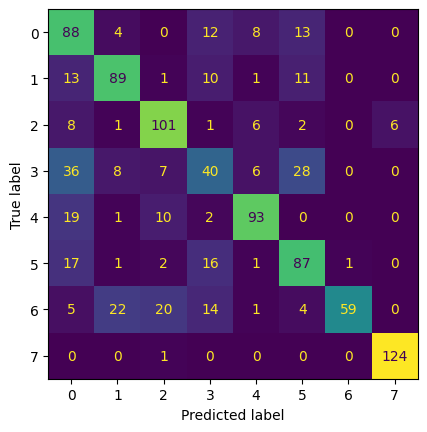

subset DT
accuracy: 0.591
              precision    recall  f1-score   support

           0     0.4359    0.4080    0.4215       125
           1     0.6094    0.6240    0.6166       125
           2     0.6777    0.6560    0.6667       125
           3     0.3800    0.4560    0.4145       125
           4     0.6500    0.6240    0.6367       125
           5     0.4563    0.3760    0.4123       125
           6     0.6136    0.6480    0.6304       125
           7     0.9070    0.9360    0.9213       125

    accuracy                         0.5910      1000
   macro avg     0.5912    0.5910    0.5900      1000
weighted avg     0.5912    0.5910    0.5900      1000



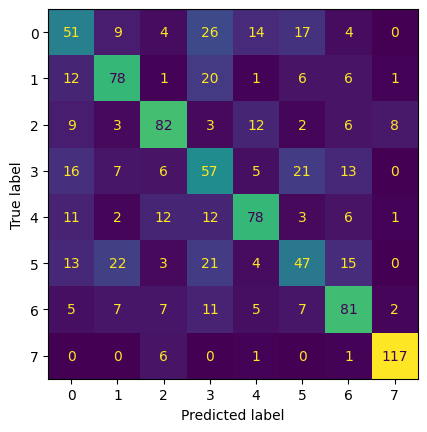

subset SGD
accuracy: 0.671
              precision    recall  f1-score   support

           0     0.3785    0.9600    0.5430       125
           1     0.9794    0.7600    0.8559       125
           2     0.9714    0.5440    0.6974       125
           3     1.0000    0.0080    0.0159       125
           4     0.8376    0.7840    0.8099       125
           5     0.7654    0.4960    0.6019       125
           6     0.5556    0.8800    0.6811       125
           7     0.9832    0.9360    0.9590       125

    accuracy                         0.6710      1000
   macro avg     0.8089    0.6710    0.6455      1000
weighted avg     0.8089    0.6710    0.6455      1000



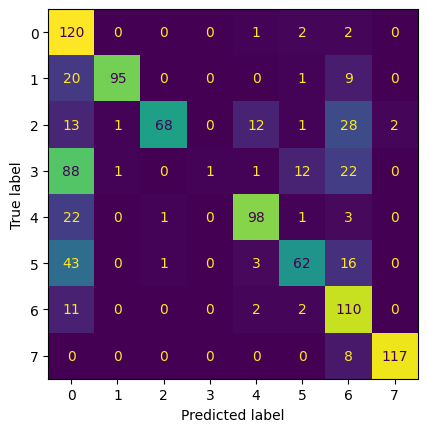

full KNN
accuracy: 0.7149956153171587
              precision    recall  f1-score   support

           0     0.4543    0.6311    0.5283       244
           1     0.7223    0.8253    0.7704       624
           2     0.6431    0.7588    0.6962       311
           3     0.5782    0.5492    0.5633       579
           4     0.7632    0.7160    0.7389       243
           5     0.5617    0.6092    0.5845       284
           6     0.9579    0.6156    0.7495       666
           7     0.9549    0.9915    0.9729       470

    accuracy                         0.7150      3421
   macro avg     0.7044    0.7121    0.7005      3421
weighted avg     0.7390    0.7150    0.7174      3421



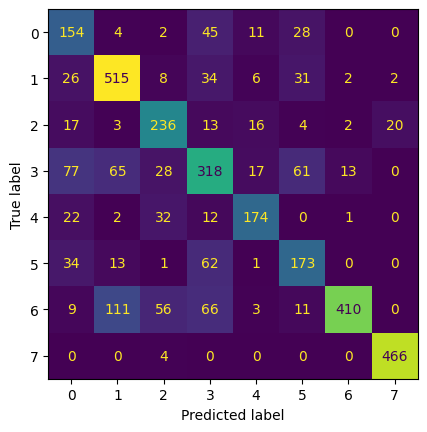

full DT
accuracy: 0.6498099970768781
              precision    recall  f1-score   support

           0     0.3885    0.4426    0.4138       244
           1     0.7371    0.7324    0.7347       624
           2     0.6552    0.6720    0.6635       311
           3     0.5009    0.4940    0.4974       579
           4     0.6218    0.6091    0.6154       243
           5     0.3667    0.3486    0.3574       284
           6     0.7195    0.7087    0.7141       666
           7     0.9467    0.9447    0.9457       470

    accuracy                         0.6498      3421
   macro avg     0.6170    0.6190    0.6177      3421
weighted avg     0.6512    0.6498    0.6504      3421



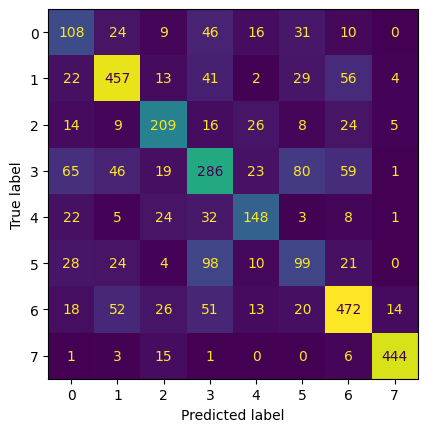

full SGD
accuracy: 0.6188249049985385
              precision    recall  f1-score   support

           0     0.9714    0.1393    0.2437       244
           1     0.9848    0.7292    0.8379       624
           2     0.9722    0.6752    0.7970       311
           3     0.5323    0.1140    0.1878       579
           4     0.8542    0.6749    0.7540       243
           5     0.2121    0.9894    0.3493       284
           6     0.7404    0.6637    0.6999       666
           7     0.9894    0.9894    0.9894       470

    accuracy                         0.6188      3421
   macro avg     0.7821    0.6219    0.6074      3421
weighted avg     0.7857    0.6188    0.6292      3421



/Users/tian/Library/Python/3.13/lib/python/site-packages/sklearn/linear_model/_stochastic_gradient.py:726: ConvergenceWarning: Maximum number of iteration reached before convergence. Consider increasing max_iter to improve the fit.
  warnings.warn(


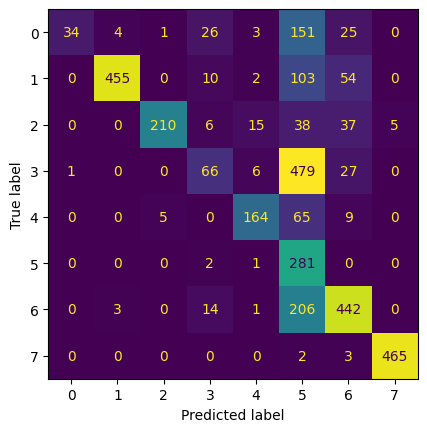

In [3]:
def make_classifiers():
    return {
        "KNN": KNeighborsClassifier(n_neighbors=3),
        "DT": DecisionTreeClassifier(),
        "SGD": SGDClassifier(max_iter=250),
    }

for experiment, (xtr, ytr, xte, yte) in experiments.items():
    for name, model in make_classifiers().items():
        np.random.seed(SEED)
        model.fit(xtr, ytr)
        pred = model.predict(xte)
        print(experiment, name)
        print("accuracy:", accuracy_score(yte, pred))
        print(classification_report(yte, pred, digits=4))
        show_cm(confusion_matrix(yte, pred))

full set is a bit better than the balanced subset for all three

knn did best here, then sgd, decision tree was weakest

more training data helps a bit, but the full set is also unbalanced so the scores are not directly comparable to the subset